# 10 Tagescluster: Tagestypen je HAST

Teil 3: Clustering

**Worum es geht**
- Jede HAST bekommt für jeden Tag eine Zeile mit wenigen, gut lesbaren Merkmalen.
- Die Tage werden nach Außentemperatur in Gruppen geteilt und je Gruppe mit K-Means geclustert.
- Frage: Welche Tagestypen gibt es, und liegen die Tage einer HAST im selben Cluster?
- Begehungen und Reparaturen sind bewusst noch nicht dabei. Das ist der nächste Schritt.

**Daten**
- liest: `data/processed/real_meters/` (Stundenraster je HAST), `data/raw/Nodes_Edges.ods` (Anschlusswert je Zähler), `data/raw/Zuordnung.xlsx` (Anschlusswert für getauschte Zähler), `external/dwd/` (Tagesmitteltemperatur der DWD-Station Kitzingen, öffentlich, gitignored)
- schreibt: `data/processed/hast_tage.csv`, `hast_tage_clusteranteile.csv`, `hast_tage.json`
- vorher ausführen: Notebook 00

**Code**
- Alles im Notebook, keine Abhängigkeit zu `src/`.

## 1 Zwei Arten von Messwerten

- Zählerstände (Energie in kWh, Volumen in m³) zählen ununterbrochen weiter, wie der Kilometerzähler im Auto. Die Differenz zweier Stände ist genau das, was dazwischen geflossen ist.
- Momentanwerte (Durchfluss, Leistung, Temperaturen) sind Momentaufnahmen zur vollen Stunde, wie ein Blick auf den Tacho. Sie sind keine Stundenmittel (Datencheck D2).

Warum das ein Problem ist:
- Eine Momentaufnahme kann zufällig eine kurze Warmwasserzapfung treffen oder genau die Pause.
- Beispiel: Jemand duscht 10 Minuten bei 600 l/h, es fließen also 100 Liter.
  - Trifft die Aufnahme die Dusche, zählt die Stunde 600 Liter.
  - Verfehlt sie die Dusche, zählt die Stunde 0 Liter.
- Eine Tagessumme aus 24 Momentaufnahmen liegt im Winter um bis zu ±30 % daneben. Im Sommer ist es noch mehr, weil dann fast nur kurze Zapfungen vorkommen.

Was das Notebook daraus macht:
- Tagesenergie und Tagesvolumen kommen aus den Zählerständen: Stand um Mitternacht minus Stand der Mitternacht davor.
- Die Streuung über den Tag kommt aus den Momentaufnahmen. Hier sind sie von Vorteil: Sie zeigen, wie stark die Werte tatsächlich springen. Ein Stundenmittel würde das glätten.

## 2 Setup und Parameter

- Pfade, Schwellen, Temperaturgruppen, Merkmale und K stehen nur in der nächsten Zelle.
- Alle Schwellen sind Startwerte. Andere sinnvolle Werte sind möglich.

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 40)
plt.rcParams["figure.facecolor"] = "white"

ROOT = Path.cwd().resolve()
while not (ROOT / "notebooks").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

METER_DIR = ROOT / "data" / "processed" / "real_meters"
NODES_PATH = ROOT / "data" / "raw" / "Nodes_Edges.ods"
ZUORDNUNG_PATH = ROOT / "data" / "raw" / "Zuordnung.xlsx"
DWD_DIR = ROOT / "external" / "dwd"
AUSGABE = ROOT / "data" / "processed" / "hast_tage.csv"

#Temperaturgruppen (Tagesmittel in °C)
GRENZEN = [-np.inf, 0, 5, 10, 15, 18, np.inf]
GRUPPEN = ["Heiz <0", "Heiz 0-5", "Heiz 5-10", "Heiz 10-15", "Uebergang 15-18", "Sommer >=18"]

#Tageszeilen
RHO_C = 1.15              #kWh je m³ und K (Wasser bei ~50 °C)
MAX_ABSTAND_H = 2         #Zählerstand darf so weit neben Mitternacht liegen
AKTIV_FLUSS_LH = 20       #ab hier läuft die Station
MIN_AKTIV_STUNDEN = 6     #weniger laufende Stunden: keine Streuung für den Tag
MIN_NACHT_STUNDEN = 4     #gemessene Stunden 0 bis 6 Uhr für den Nachtfluss

#Markierungen, gelöscht wird nichts
MIN_STUNDEN = 12          #gemessene Stunden je Tag (Lauf 1: 20)
MIN_ENERGIE_KWH = 5       #Zähler zählt ganze kWh, so bleibt der Fehler unter 20 % (Lauf 1: 10)
MAX_KWH_PRO_M3 = 70       #entspricht ~60 K Spreizung, unplausibel
STEHT_LEISTUNG_KW = 1.0   #Energiezähler steht, obwohl so viel Leistung anliegt

#Clustering
MERKMALE_HEIZ = ["kwh_pro_m3", "volumen_m3_pro_kw", "spreizung_p90_p10_k", "fluss_cv"]
MERKMALE_SOMMER = ["kwh_pro_m3", "volumen_m3_pro_kw", "nachtfluss_lh_pro_kw"]
MERKMALE_JE_GRUPPE = {g: MERKMALE_HEIZ for g in GRUPPEN}
MERKMALE_JE_GRUPPE["Uebergang 15-18"] = MERKMALE_SOMMER  #Lauf 1: Heiz-Merkmale
MERKMALE_JE_GRUPPE["Sommer >=18"] = MERKMALE_SOMMER
K_JE_GRUPPE = {g: 4 for g in GRUPPEN}   #nach Abschnitt 7 anpassen (2 bis 5)
K_JE_GRUPPE["Uebergang 15-18"] = 3      #Lauf 1: 4
K_JE_GRUPPE["Sommer >=18"] = 3          #Lauf 1: 4
K_TEST = range(2, 7)
MIN_TAGE_JE_HAST = 10     #für die Frage, ob die Tage einer HAST zusammenliegen
SEED = 42

#Farben: hell = gut, dunkel = schlecht
#Heiztage blau, Übergang/Sommer orange
CLUSTER_FARBEN = {
    2: ["#86b6ef", "#0d366b"],
    3: ["#86b6ef", "#2a78d6", "#0d366b"],
    4: ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"],
    5: ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"],
}
CLUSTER_FARBEN_SOMMER = {
    2: ["#fe9670", "#662000"],
    3: ["#fe9670", "#c74b12", "#662000"],
    4: ["#fe9670", "#e26331", "#b33f01", "#7b2902"],
    5: ["#fe9670", "#ea6b3a", "#c74b12", "#9c3602", "#712400"],
}
FARBE_TATSAECHLICH, FARBE_ZUFALL = "#4a3aa7", "#1baf7a"   #violett/türkis, unabhängig von den Familien
TINTE, TINTE_LEISE, GITTER, ACHSE, FLAECHE = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BUCHSTABEN = "ABCDE"
assert all(2 <= k <= 5 for k in K_JE_GRUPPE.values()), "K muss zwischen 2 und 5 liegen"


def ist_sommerfamilie(gruppe):
    """Gruppen mit den Sommer-Merkmalen (Uebergang, Sommer) bilden Familie 2."""
    return MERKMALE_JE_GRUPPE[gruppe] == MERKMALE_SOMMER


def farben_fuer(gruppe, k):
    """Blaustufen fuer Familie 1 (Heiztage), Orangestufen fuer Familie 2."""
    return (CLUSTER_FARBEN_SOMMER if ist_sommerfamilie(gruppe) else CLUSTER_FARBEN)[k]


def stil(ax):
    """Zurueckhaltende Achsen: nur links/unten, feines Gitter."""
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(ACHSE)
    ax.tick_params(colors=TINTE_LEISE, labelsize=9)
    ax.grid(color=GITTER, linewidth=0.6)
    ax.set_axisbelow(True)

- Pfade: Zählerdaten aus Notebook 00 (`real_meters`), Anschlusswerte aus `Nodes_Edges.ods` und `Zuordnung.xlsx`, Wetter der DWD-Station Kitzingen, Ergebnis nach `hast_tage.csv`.
- Sechs Temperaturgruppen: Heiztage unter 0, 0–5, 5–10 und 10–15 °C, Übergang 15–18 °C, Sommer ab 18 °C. Verglichen werden nur Tage mit ähnlichem Wetter.
  - Heiztage in 5-K-Bändern, weil sich der Volumenstrom zwischen −10 und +10 °C stark ändert.
  - Unter −5 °C gab es 2021–2025 nur 14 Tage, deshalb ein gemeinsames Band „unter 0“.
- Markieren statt löschen: Tage mit unter 12 Messstunden, unter 5 kWh oder über 70 kWh/m³ werden markiert. Sie bleiben in der Tabelle, fließen aber nicht ins Clustering ein.
- Clustermerkmale (`MERKMALE_JE_GRUPPE`):
  - Heiztage: `kwh_pro_m3` (Abkühlung, entspricht der mengengewichteten Spreizung × 1,15), `volumen_m3_pro_kw` (Tagesvolumen je kW Anschlusswert, unabhängig von der Hausgröße), `spreizung_p90_p10_k` (wie stark die Spreizung über den Tag schwankt), `fluss_cv` (wie stark der Durchfluss über den Tag schwankt)
  - Übergang und Sommer: `kwh_pro_m3`, `volumen_m3_pro_kw` und Nachtfluss je kW statt der beiden Streuungen. Nachts sollte dann kaum Wasser fließen, und an vielen Tagen läuft die Station zu selten für eine Streuung.
- Spreizung = Vorlauf minus Rücklauf. Sie wird mitgeführt, aber nicht geclustert: Sie ist kWh/m³ ÷ 1,15 und würde die Abkühlung doppelt zählen.
- K = 4 an Heiztagen, K = 3 in Übergang und Sommer. Erlaubt sind 2 bis 5, bei mehr Stufen lassen sich die Farben nicht mehr sicher unterscheiden. `SEED = 42`, damit jeder Lauf dasselbe Ergebnis liefert.
- Farben: Blaustufen für Heiztage, Orangestufen für Übergang und Sommer. Hell = gute Abkühlung, dunkel = schlechte.

### 2.1 Änderungen in Lauf 2 (04.10.2026)

| Einstellung | Lauf 1 | Lauf 2 | Grund aus Lauf 1 |
|---|---|---|---|
| `MIN_STUNDEN` | 20 | 12 | 17.339 Tage nur wegen zu weniger Stunden markiert; Zählerstände brauchen keine vollständigen Tage |
| `MIN_ENERGIE_KWH` | 10 | 5 | im Sommer 46 % der Tage unter 10 kWh; der Rundungsfehler bleibt unter 20 % |
| Merkmale Übergang | Heiz-Merkmale | Sommer-Merkmale | einem Drittel der nutzbaren Übergangstage fehlte die Streuung |
| K Übergang / Sommer | 4 / 4 | 3 / 3 | Sommer trennt sich klar in Normalbetrieb und Dauerdurchfluss (Silhouette 0,78 bei K = 2), bei K = 4 zerfiel der Dauerdurchfluss in zwei Cluster |
| Clusterbuchstaben | je Gruppe nach kWh/m³ | über die Gruppen abgeglichen | derselbe Typ hieß in „Heiz <0“ C, in den anderen Heizgruppen B |
| Farben Übergang/Sommer (05.10.) | Blaustufen | Orangestufen | sonst mit den Heiztag-Typen verwechselbar, vor allem im Zeitverlauf |

Ergebnis von Lauf 1:
- An Heiztagen entstanden in allen Bändern dieselben vier Typen: gute Abkühlung, stark schwankend, gleichmäßig schwach, Dauerdurchfluss.
- Die Tage einer HAST lagen deutlich häufiger im selben Cluster als bei Zufall.
- Klare Gruppen gab es nur im Sommer.

## 3 Wetter: Tagesmitteltemperatur und Gruppen

- `lade_dwd()` liest alle DWD-Dateien `produkt_klima_tag_*.txt` aus `external/dwd/`. Eine neuere Datei wird automatisch mitgelesen.
- Genutzt werden Datum, Qualitätsstufe (`QN_4`) und Tagesmitteltemperatur (`TMK`). Überlappen zwei Dateien, gewinnt die besser geprüfte Zeile.
- `pd.cut` ordnet jedem Tag genau eine der sechs Gruppen zu. Die Tabelle zeigt die Tage je Jahr und Gruppe ab 2022.

In [2]:
def lade_dwd(ordner):
    """Tagesmitteltemperatur (TMK) aus allen produkt_klima_tag-Dateien im Ordner."""
    dateien = sorted(Path(ordner).rglob("produkt_klima_tag_*.txt"))
    if not dateien:
        raise FileNotFoundError(f"keine DWD-Datei unter {ordner}")
    teile = []
    for f in dateien:
        d = pd.read_csv(f, sep=";", skipinitialspace=True)
        d.columns = d.columns.str.strip()
        teile.append(d[["MESS_DATUM", "QN_4", "TMK"]])
    w = pd.concat(teile, ignore_index=True)
    w["datum"] = pd.to_datetime(w["MESS_DATUM"].astype(str), format="%Y%m%d").astype("datetime64[ns]")
    w["TMK"] = w["TMK"].where(w["TMK"] != -999)
    w = w.sort_values("QN_4", ascending=False).drop_duplicates("datum")
    return w.set_index("datum").sort_index()["TMK"].rename("t_mittel_c")


wetter = lade_dwd(DWD_DIR)
wetter_gruppe = pd.cut(wetter, GRENZEN, right=False, labels=GRUPPEN)
print(f"Wetter: {wetter.index.min().date()} bis {wetter.index.max().date()}, "
      f"fehlende Tagesmittel: {int(wetter.isna().sum())}")
ab = wetter.index >= "2022-01-01"
display(pd.crosstab(wetter.index.year[ab].to_numpy(), wetter_gruppe[ab].to_numpy(),
                    rownames=["jahr"], colnames=["gruppe"]).reindex(columns=GRUPPEN, fill_value=0))

Wetter: 1982-11-01 bis 2025-12-31, fehlende Tagesmittel: 0


gruppe,Heiz <0,Heiz 0-5,Heiz 5-10,Heiz 10-15,Uebergang 15-18,Sommer >=18
jahr,,,,,,
2022,12,76,77,68,32,100
2023,17,57,82,67,50,92
2024,21,43,91,74,46,91
2025,30,65,69,80,47,74


- Station Kitzingen (DWD 2600), rund 13 km von Wiesentheid, vollständig geprüft (Qualitätsstufe 10).
- Die Daten reichen bis 31.12.2025, ohne fehlenden Tag. Für 2026 gibt es ohnehin keine Zählerstände (Check D2). Diese Tage werden als `ohne_wetter` markiert.
- Pro Jahr gibt es 32–50 Übergangstage und 74–100 Sommertage. 2022 hatte die meisten Sommertage (100), 2025 die meisten Frosttage (30).
- „Heiz <0“ ist mit 12–30 Tagen pro Jahr die kleinste Gruppe. Deshalb ist alles unter 0 °C zusammengefasst.

## 4 Anschlusswert je Zähler

- Anschlusswert = vertraglich vereinbarte Höchstleistung in kW, die ein Gebäude gleichzeitig aus dem Netz beziehen darf.
- Zuerst direkt über die Zählernummer in `Nodes_Edges.ods`. Fehlt sie dort, weil der Zähler getauscht wurde, über die Adresse in `Zuordnung.xlsx`.
- Die Adress-Normierung ist eine Kopie aus `src/`, damit das Notebook eigenständig bleibt.

In [3]:
def adresse_norm(s):
    """Wie _normalize_address in src/load_data.py plus Tippfehler aus src/load_begehungen.py.

    Bewusst hier dupliziert, damit das Notebook eigenstaendig bleibt.
    """
    if not isinstance(s, str):
        return ""
    t = s.lower().strip().replace("ß", "ss")
    t = t.replace("ä", "ae").replace("ö", "oe").replace("ü", "ue")
    t = re.sub(r"\.", "", t)
    t = re.sub(r"str(asse)?\b", "strasse", t)
    t = re.sub(r"\s+", " ", t)
    t = re.sub(r"[^a-z0-9 \-]", "", t)
    t = re.sub(r"(\d)\s+([a-z])\b", r"\1\2", t)
    t = re.sub(r"\s*-\s*", "-", t)
    return t.strip().replace("fleiderstrasse", "fliederstrasse")


zaehler_dateien = sorted(METER_DIR.glob("*.csv"))
if not zaehler_dateien:
    raise FileNotFoundError(f"keine Zaehlerdateien in {METER_DIR} - zuerst Notebook 00 ausfuehren")

#Anschlusswert je Zählernummer aus Nodes_Edges
nodes = pd.read_excel(NODES_PATH, sheet_name="Nodes")
nodes["zaehler"] = pd.to_numeric(nodes["Zählernummer"], errors="coerce")
nodes["aw"] = pd.to_numeric(nodes["Anschlusswert"], errors="coerce")
nodes = nodes.dropna(subset=["zaehler"])
nodes["zaehler"] = nodes["zaehler"].astype(int)
aw_direkt = nodes[nodes["aw"] > 0].groupby("zaehler")["aw"].max()
aw_je_adresse = {}
for adresse, aw in zip(nodes["Straße"], nodes["aw"]):
    if aw > 0:
        aw_je_adresse.setdefault(adresse_norm(adresse), set()).add(float(aw))

#Zuordnung.xlsx: ein Blatt je Jahr, 2026 mit Straße und Hausnummer getrennt
blaetter = []
for blatt in pd.ExcelFile(ZUORDNUNG_PATH).sheet_names:
    z = pd.read_excel(ZUORDNUNG_PATH, sheet_name=blatt)
    sp = list(z.columns)
    if len(sp) > 3 and "Hausnr" in str(sp[2]):
        adresse = z[sp[1]].astype(str).str.strip() + " " + z[sp[2]].astype(str).str.strip()
    else:
        adresse = z[sp[2]]
    blaetter.append(pd.DataFrame({"zaehler": pd.to_numeric(z[sp[0]], errors="coerce"),
                                  "adresse": adresse}))
zuordnung = pd.concat(blaetter, ignore_index=True).dropna()
zuordnung["zaehler"] = zuordnung["zaehler"].astype(int)
zuordnung["key"] = zuordnung["adresse"].map(adresse_norm)
zuordnung = zuordnung[zuordnung["key"].str.len() > 3]

anschluss, quelle = {}, {}
for z in (int(p.stem) for p in zaehler_dateien):
    if z in aw_direkt.index:
        anschluss[z], quelle[z] = float(aw_direkt[z]), "Nodes_Edges"
        continue
    kandidaten = set()
    for key in set(zuordnung.loc[zuordnung["zaehler"] == z, "key"]):
        kandidaten |= aw_je_adresse.get(key, set())
    if len(kandidaten) == 1:
        anschluss[z], quelle[z] = kandidaten.pop(), "Zuordnung (Adresse)"
    else:
        quelle[z] = "mehrdeutig" if kandidaten else "fehlt"

print("Herkunft des Anschlusswerts (Anzahl Zaehler):")
print(pd.Series(quelle).value_counts().to_string())

Herkunft des Anschlusswerts (Anzahl Zaehler):
Nodes_Edges            85
fehlt                   4
Zuordnung (Adresse)     3
mehrdeutig              1


- Ergebnis wie laut Check D2 erwartet: 85 Zähler direkt, 3 über die Adresse, 1 mehrdeutig, 4 ohne Wert.
- Zähler ohne Anschlusswert bleiben in der Tabelle, fallen aber aus dem Clustering, weil `volumen_m3_pro_kw` fehlt.

Was der Anschlusswert bedeutet:
- Er ist auf den kältesten Tag ausgelegt (Heizlast und Warmwasser). Danach werden HAST, Wärmetauscher und Regelventil bemessen.
- Der Kunde zahlt dafür üblicherweise einen Grundpreis je kW, egal wie viel er tatsächlich verbraucht.
- In unseren Daten typisch 5–17 kW (Wohnhäuser), zwei große Verbraucher mit 500 kW. Quelle ist immer `Nodes_Edges.ods`, `Zuordnung.xlsx` dient nur als Brücke.
- Der Wert allein sagt nichts über gut oder schlecht. Er ist nur eine Größenangabe. Erst das Volumen je kW zeigt das Verhalten.

Beispiel Anschlusswert 8 kW:
- Höchstens 8 kW gleichzeitig, also maximal 8 × 24 = 192 kWh am Tag. Bei 0–5 °C werden meist nur etwa 2–3 kW genutzt.
- Wasserbedarf bei voller Leistung: rund 230 l/h bei 30 K Spreizung, aber rund 460 l/h bei 15 K. Schlechte Abkühlung kostet doppelt so viel Wasser.
- Typ A (gute Abkühlung) braucht bei 0–5 °C rund 1,8 m³ am Tag, Typ D (Dauerdurchfluss) 8–10 m³. Die Typen stehen in Abschnitt 9.

## 5 Tageszeilen bauen

- Tagesenergie und Tagesvolumen: Differenz der Zählerstände von Mitternacht zu Mitternacht. Fehlt der Stand um 0 Uhr, nimmt die Zelle den nächsten im Abstand von höchstens 2 h und rechnet auf 24 h um. Lücken mitten am Tag stören nicht, weil der Zähler weiterzählt.
- kWh/m³ = Tagesenergie ÷ Tagesvolumen. Das ist die mengengewichtete Spreizung × 1,15 und unabhängig von der Hausgröße.
- Streuung aus den Momentaufnahmen, nur Stunden ab 20 l/h (mindestens 6): Spreizung p90 − p10 und Variationskoeffizient des Durchflusses (Standardabweichung ÷ Mittelwert).
- Nachtfluss = kleinster Durchfluss zwischen 0 und 6 Uhr. Vor- und Rücklauf mengengewichtet, nur zum Mitlesen.

In [4]:
SPALTEN = {
    "Energy (kWh)": "energie", "Volume flow (l/h)": "fluss", "Power (kW)": "leistung",
    "Temperature difference (°C)": "spreizung", "Flow temperature (°C)": "vorlauf",
    "Return temperature (°C)": "ruecklauf", "Volume (m³)": "volumen",
}


def zaehler_differenz(gem, tage_idx):
    """Energie und Volumen je Tag aus den Zaehlerstaenden um Mitternacht."""
    staende = gem[["energie", "volumen"]].dropna().rename_axis("ts").reset_index()
    if staende.empty:
        return pd.DataFrame(index=tage_idx, columns=["energie_kwh", "volumen_m3", "zaehler_spanne_h"],
                            dtype=float)
    grenzen = pd.DataFrame({"grenze": pd.date_range(tage_idx.min(), tage_idx.max() + pd.Timedelta(days=1),
                                                    freq="D").astype("datetime64[ns]")})
    nah = pd.merge_asof(grenzen, staende, left_on="grenze", right_on="ts", direction="nearest",
                        tolerance=pd.Timedelta(hours=MAX_ABSTAND_H))
    a, b = nah.iloc[:-1].reset_index(drop=True), nah.iloc[1:].reset_index(drop=True)
    spanne = (b["ts"] - a["ts"]).dt.total_seconds() / 3600
    out = pd.DataFrame({
        "energie_kwh": (b["energie"] - a["energie"]) * 24 / spanne,
        "volumen_m3": (b["volumen"] - a["volumen"]) * 24 / spanne,
        "zaehler_spanne_h": spanne,
    })
    out.index = pd.DatetimeIndex(a["grenze"])
    return out.reindex(tage_idx)


def tageswerte(pfad):
    """Eine Zeile je Tag fuer einen Zaehler."""
    df = pd.read_csv(pfad, parse_dates=["Timestamp"]).rename(columns=SPALTEN)
    df = df.set_index("Timestamp").sort_index()
    df.index = df.index.astype("datetime64[ns]")
    gem = df.dropna(subset=["fluss"])                     #nur gemessene Stunden
    if gem.empty:
        return None
    tag = gem.index.normalize()
    tage_idx = tag.unique()

    g = gem.groupby(tag)
    out = pd.DataFrame({"n_stunden": g.size(),
                        "fluss_mittel_lh": g["fluss"].mean(),
                        "leistung_mittel_kw": g["leistung"].mean()})

    q = gem["fluss"].clip(lower=0)
    s = pd.DataFrame({"q": q, "qv": q * gem["vorlauf"], "qr": q * gem["ruecklauf"]}).groupby(tag).sum()
    out["vorlauf_c"] = s["qv"] / s["q"].where(s["q"] > 0)
    out["ruecklauf_c"] = s["qr"] / s["q"].where(s["q"] > 0)

    akt = gem[gem["fluss"] >= AKTIV_FLUSS_LH]
    ga = akt.groupby(akt.index.normalize())
    out["n_aktiv"] = ga.size().reindex(tage_idx, fill_value=0)
    genug = out["n_aktiv"] >= MIN_AKTIV_STUNDEN
    p90_p10 = ga["spreizung"].quantile(0.9) - ga["spreizung"].quantile(0.1)
    out["spreizung_p90_p10_k"] = p90_p10.reindex(tage_idx).where(genug)
    out["fluss_cv"] = (ga["fluss"].std() / ga["fluss"].mean()).reindex(tage_idx).where(genug)

    nacht = gem[gem.index.hour < 6]
    gn = nacht.groupby(nacht.index.normalize())["fluss"]
    out["nachtfluss_lh"] = gn.min().clip(lower=0).where(gn.size() >= MIN_NACHT_STUNDEN).reindex(tage_idx)

    out = out.join(zaehler_differenz(gem, tage_idx))
    out["kwh_pro_m3"] = out["energie_kwh"] / out["volumen_m3"].where(out["volumen_m3"] > 0)
    out["spreizung_k"] = out["kwh_pro_m3"] / RHO_C
    out.index.name = "datum"
    return out.reset_index().assign(zaehler=int(pfad.stem))


teile = [tageswerte(p) for p in zaehler_dateien]
tage = pd.concat([t for t in teile if t is not None], ignore_index=True)
tage["anschlusswert_kw"] = tage["zaehler"].map(anschluss)
tage["volumen_m3_pro_kw"] = tage["volumen_m3"] / tage["anschlusswert_kw"]
tage["nachtfluss_lh_pro_kw"] = tage["nachtfluss_lh"] / tage["anschlusswert_kw"]
tage["t_mittel_c"] = tage["datum"].map(wetter)
tage["gruppe"] = pd.cut(tage["t_mittel_c"], GRENZEN, right=False, labels=GRUPPEN)
print(f"{len(tage):,} Tageszeilen aus {tage['zaehler'].nunique()} Zaehlern, "
      f"{tage['datum'].min().date()} bis {tage['datum'].max().date()}")

85,983 Tageszeilen aus 93 Zaehlern, 2021-11-01 bis 2026-07-20


- Eine Zeile ist eine HAST an einem Tag. Gezählt werden nur Tage mit mindestens einer gemessenen Stunde.
- Ergebnis: 85.983 Tageszeilen von 93 Zählern (11/2021 bis 07/2026), noch mit unbrauchbaren Tagen.
- Anschlusswert, Temperatur und Gruppe sind angehängt. Damit gibt es Volumen und Nachtfluss je kW.
- Einschränkung: Zählertausch ist nicht zusammengeführt. Eine HAST mit Tausch erscheint als zwei Zähler.

## 6 Tage markieren statt löschen

- Jeder Tag wird auf acht mögliche Probleme geprüft. Gelöscht wird nichts.

In [5]:
gruende = {
    "kein_zaehlerstand": tage["energie_kwh"].isna() | tage["volumen_m3"].isna(),
    "ruecksprung": (tage["energie_kwh"] < 0) | (tage["volumen_m3"] < 0),
    "zaehler_steht": ((tage["volumen_m3"] == 0) & (tage["fluss_mittel_lh"] >= AKTIV_FLUSS_LH))
                     | ((tage["energie_kwh"] == 0) & (tage["leistung_mittel_kw"] >= STEHT_LEISTUNG_KW)),
    "wenig_energie": tage["energie_kwh"] < MIN_ENERGIE_KWH,
    "unplausibel": tage["kwh_pro_m3"] > MAX_KWH_PRO_M3,
    "wenig_stunden": tage["n_stunden"] < MIN_STUNDEN,
    "ohne_wetter": tage["gruppe"].isna(),
}
steht = tage.loc[gruende["zaehler_steht"], ["zaehler", "datum"]]
folgetag = pd.MultiIndex.from_arrays([steht["zaehler"], steht["datum"] + pd.Timedelta(days=1)])
gruende["nach_stillstand"] = pd.Series(
    pd.MultiIndex.from_arrays([tage["zaehler"], tage["datum"]]).isin(folgetag), index=tage.index)

grund = pd.Series("", index=tage.index)
for name, maske in gruende.items():
    grund = grund.where(~maske, grund + name + ", ")
tage["grund"] = grund.str.rstrip(", ")
tage["nutzbar"] = tage["grund"] == ""

uebersicht = pd.DataFrame({"Tage": tage.groupby("gruppe", observed=False).size(),
                           "nutzbar": tage[tage["nutzbar"]].groupby("gruppe", observed=False).size()})
for name, maske in gruende.items():
    if name != "ohne_wetter":
        uebersicht[name] = maske.groupby(tage["gruppe"], observed=False).sum()
display(uebersicht)
print(f"ohne Wetter (z. B. 2026): {int(gruende['ohne_wetter'].sum()):,} Tage")
print(f"nutzbar insgesamt: {int(tage['nutzbar'].sum()):,} von {len(tage):,} Tagen")

,Tage,nutzbar,kein_zaehlerstand,ruecksprung,zaehler_steht,wenig_energie,unplausibel,wenig_stunden,nach_stillstand
gruppe,,,,,,,,,
Heiz <0,5117,4761,51,1,0,47,0,258,0
Heiz 0-5,14887,10881,138,2,0,131,0,3752,0
Heiz 5-10,19911,15895,263,0,3,291,0,3597,2
Heiz 10-15,16839,13093,191,0,1,865,0,2842,2
Uebergang 15-18,9371,6839,160,0,1,1254,3,1360,1
Sommer >=18,18853,11265,349,0,19,4133,16,4236,19


ohne Wetter (z. B. 2026): 1,005 Tage
nutzbar insgesamt: 62,734 von 85,983 Tagen


| Markierung | Bedeutung |
|---|---|
| `kein_zaehlerstand` | kein Zählerstand nahe Mitternacht, z. B. ODS-Zeiträume oder Lücken |
| `ruecksprung` | Zählerstand sinkt: Zählertausch oder Reset |
| `zaehler_steht` | Zählerstand bewegt sich nicht, obwohl laut Momentaufnahmen Wasser fließt bzw. Leistung anliegt |
| `nach_stillstand` | Tag nach einem stehenden Zähler: Dort holt der Zähler meist auf |
| `wenig_energie` | unter 5 kWh am Tag: Rundung auf ganze kWh macht kWh/m³ ungenau |
| `unplausibel` | über 70 kWh/m³ |
| `wenig_stunden` | weniger als 12 gemessene Stunden |
| `ohne_wetter` | kein Tagesmittel vorhanden |

- Ein Tag kann mehrere Markierungen haben. `grund` listet alle, `nutzbar` heißt: keine Markierung.
- 62.734 von 85.983 Tagen sind nutzbar (73 %). Heiz <0 93 %, übrige Heizgruppen 73–80 %, Übergang 73 %, Sommer nur 60 %.
- Größter Verlust: unter 12 Messstunden (16.045 Tage), Grund noch offen. Danach unter 5 kWh (6.721 Tage, davon 4.133 im Sommer): Kleine Häuser brauchen im Sommer wenig Warmwasser.
- Die Zählerstände sind fast immer in Ordnung: Rücksprung 3, Zähler steht 24, unplausibel 19. Im Sommer bleiben eher größere, verbrauchsstarke Stationen übrig. Die Sommer-Ergebnisse sind etwas in diese Richtung verzerrt.

## 7 Merkmale ansehen

- Verteilung der fünf Merkmale über alle nutzbaren Tage und ihre Rangkorrelation (Spearman).

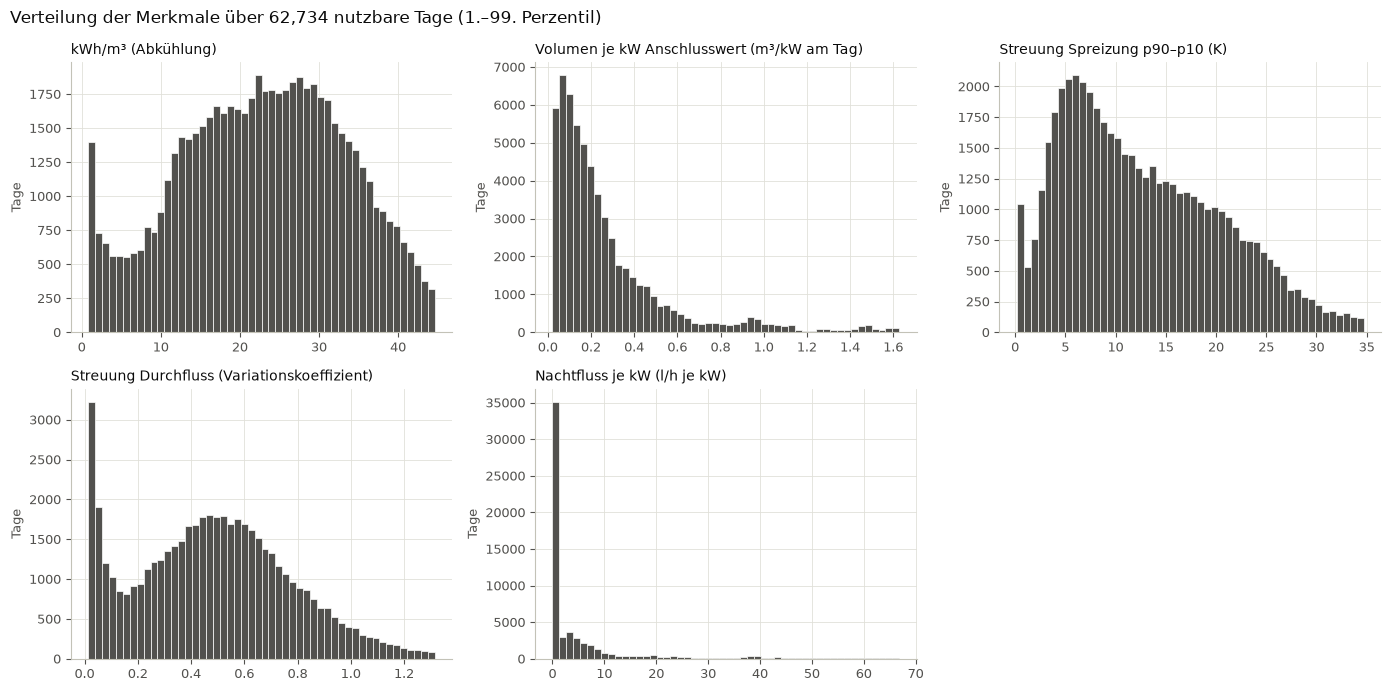

Rangkorrelation (Spearman) der Merkmale:


,kwh_pro_m3,volumen_m3_pro_kw,spreizung_p90_p10_k,fluss_cv,nachtfluss_lh_pro_kw
kwh_pro_m3,1.00,-0.22,0.28,0.35,-0.15
volumen_m3_pro_kw,-0.22,1.00,-0.09,-0.48,0.63
spreizung_p90_p10_k,0.28,-0.09,1.00,0.40,-0.23
fluss_cv,0.35,-0.48,0.40,1.00,-0.49
nachtfluss_lh_pro_kw,-0.15,0.63,-0.23,-0.49,1.00


In [6]:
BESCHRIFTUNG = {
    "kwh_pro_m3": "kWh/m³ (Abkühlung)",
    "volumen_m3_pro_kw": "Volumen je kW Anschlusswert (m³/kW am Tag)",
    "spreizung_p90_p10_k": "Streuung Spreizung p90–p10 (K)",
    "fluss_cv": "Streuung Durchfluss (Variationskoeffizient)",
    "nachtfluss_lh_pro_kw": "Nachtfluss je kW (l/h je kW)",
}
nutz = tage[tage["nutzbar"]]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, sp in zip(axes.flat, BESCHRIFTUNG):
    w = nutz[sp].dropna()
    unten, oben = w.quantile([0.01, 0.99])
    ax.hist(w, bins=50, range=(unten, oben), color=TINTE_LEISE, edgecolor="white", linewidth=0.5)
    ax.set_title(BESCHRIFTUNG[sp], loc="left", fontsize=10, color=TINTE)
    ax.set_ylabel("Tage", fontsize=9, color=TINTE_LEISE)
    stil(ax)
axes.flat[-1].axis("off")
fig.suptitle(f"Verteilung der Merkmale über {len(nutz):,} nutzbare Tage (1.–99. Perzentil)",
             x=0.01, ha="left", color=TINTE)
fig.tight_layout()
plt.show()

print("Rangkorrelation (Spearman) der Merkmale:")
display(nutz[list(BESCHRIFTUNG)].corr(method="spearman").round(2))

- Schiefe Verteilungen sind normal. Für das Clustering werden Ausreißer je Gruppe auf das 1.–99. Perzentil begrenzt und danach standardisiert.
- Hängen zwei Merkmale sehr eng zusammen (|Korrelation| über 0,8), messen sie fast dasselbe und zählen im Clustering doppelt.
- Hier liegt keine Korrelation über 0,8. Am engsten hängen Volumen je kW und Nachtfluss je kW zusammen (0,63).

## 8 Wie viele Cluster? Silhouette je Gruppe

- Silhouette = wie klar die Tage zu ihrem Cluster gehören: 1 = klar getrennt, 0 = auf der Grenze. Unter 0,25 gilt die Struktur als schwach (Kontinuum statt Gruppen).
- Getestet werden K = 2 bis 6 je Temperaturgruppe.

In [7]:
def matrix(gruppe):
    """Nutzbare Tage einer Gruppe und ihre standardisierte Merkmalsmatrix."""
    sp = MERKMALE_JE_GRUPPE[gruppe]
    teil = tage[(tage["gruppe"] == gruppe) & tage["nutzbar"]].dropna(subset=sp)
    if len(teil) < 50:
        return teil, None
    X = teil[sp].clip(teil[sp].quantile(0.01), teil[sp].quantile(0.99), axis=1)
    return teil, StandardScaler().fit_transform(X)


zeilen = []
for gruppe in GRUPPEN:
    teil, Z = matrix(gruppe)
    zeile = {"gruppe": gruppe, "nutzbar": int(((tage["gruppe"] == gruppe) & tage["nutzbar"]).sum()),
             "mit allen Merkmalen": len(teil), "HAST": teil["zaehler"].nunique()}
    for k in K_TEST:
        if Z is not None and len(teil) > 10 * k:
            lab = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(Z)
            zeile[f"k={k}"] = silhouette_score(Z, lab, sample_size=min(5000, len(Z)), random_state=SEED)
    zeilen.append(zeile)
silhouette = pd.DataFrame(zeilen).set_index("gruppe")
display(silhouette.round(3))

,nutzbar,mit allen Merkmalen,HAST,k=2,k=3,k=4,k=5,k=6
gruppe,,,,,,,,
Heiz <0,4761,4519,88,0.330,0.288,0.267,0.262,0.261
Heiz 0-5,10881,10247,88,0.365,0.294,0.282,0.278,0.278
Heiz 5-10,15895,14487,88,0.412,0.295,0.300,0.291,0.271
Heiz 10-15,13093,10360,88,0.404,0.298,0.287,0.302,0.274
Uebergang 15-18,6839,6593,88,0.739,0.494,0.529,0.474,0.490
Sommer >=18,11265,10917,87,0.743,0.503,0.540,0.484,0.497


- `mit allen Merkmalen` und `HAST` zeigen, wie viel tatsächlich geclustert wird. Liegt der Wert deutlich unter `nutzbar`, fehlen meist die Streuungen: Die Station lief weniger als 6 Stunden mit Durchfluss. Dann für diese Gruppe die Sommer-Merkmale nehmen (`MERKMALE_JE_GRUPPE` in Abschnitt 2).
- Heiztage: Silhouette 0,33–0,41 bei K = 2, bei K = 4 nur 0,27–0,30. Das liegt knapp über der Grenze von 0,25.
- Übergang und Sommer: 0,739 und 0,743 bei K = 2, 0,494 und 0,503 bei K = 3. Hier gibt es klare Gruppen.
- K wird fest gesetzt (`K_JE_GRUPPE` in Abschnitt 2), nicht automatisch nach der höchsten Silhouette. Kleine Unterschiede sind Rauschen.

## 9 Clustern und Cluster beschreiben

- Jede Gruppe wird für sich geclustert. Danach bekommen die Cluster über die Gruppen hinweg einheitliche Buchstaben.
- Referenz ist je Familie die Gruppe mit den meisten Tagen. Ihre Cluster sind nach Abkühlung geordnet: A hat die höchste kWh/m³, der letzte Buchstabe die niedrigste.
- Jedes Cluster der anderen Gruppen bekommt den Buchstaben des ähnlichsten Referenzclusters. Jeder Buchstabe wird genau einmal vergeben.

In [8]:
tage["cluster_rang"] = np.nan
roh = {}
for gruppe in GRUPPEN:
    k = K_JE_GRUPPE[gruppe]
    teil, Z = matrix(gruppe)
    if Z is None or len(teil) <= 10 * k:
        print(f"{gruppe}: zu wenige Tage ({len(teil)}), uebersprungen")
        continue
    roh[gruppe] = {"teil": teil, "Z": Z, "k": k,
                   "km": KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)}

familien = {}
for gruppe, e in roh.items():
    familien.setdefault((tuple(MERKMALE_JE_GRUPPE[gruppe]), e["k"]), []).append(gruppe)

ergebnisse, abgleich = {}, []
for (_, k), mitglieder in familien.items():
    ref = max(mitglieder, key=lambda g: len(roh[g]["teil"]))
    r = roh[ref]
    reihenfolge = (r["teil"].groupby(r["km"].labels_)["kwh_pro_m3"].median()
                   .sort_values(ascending=False).index.to_numpy())
    ref_zentren = r["km"].cluster_centers_[reihenfolge]
    for gruppe in mitglieder:
        e = roh[gruppe]
        kosten = np.sqrt(((e["km"].cluster_centers_[:, None, :] - ref_zentren[None, :, :]) ** 2).sum(axis=2))
        label, rang = linear_sum_assignment(kosten)
        rang_je_label = dict(zip(label, rang))
        rang_je_tag = np.array([rang_je_label[lab] for lab in e["km"].labels_])
        tage.loc[e["teil"].index, "cluster_rang"] = rang_je_tag
        ergebnisse[gruppe] = {"teil": e["teil"], "Z": e["Z"], "rang": rang_je_tag, "k": k, "referenz": ref}
        abgleich.append({"gruppe": gruppe, "referenz": ref, "K": k,
                         "mittlerer Zentrenabstand": kosten[label, rang].mean()})
ergebnisse = {g: ergebnisse[g] for g in GRUPPEN if g in ergebnisse}
print("Abgleich mit der Referenzgruppe (Abstand in Standardabweichungen, 0 = gleiche Typen):")
display(pd.DataFrame(abgleich).set_index("gruppe").reindex(list(ergebnisse)).round(2))

tage["cluster"] = tage["cluster_rang"].map(lambda r: BUCHSTABEN[int(r)], na_action="ignore")
geclustert = tage.dropna(subset=["cluster"])

PROFIL = ["kwh_pro_m3", "spreizung_k", "volumen_m3_pro_kw", "spreizung_p90_p10_k", "fluss_cv",
          "nachtfluss_lh_pro_kw", "ruecklauf_c", "t_mittel_c"]
profil = geclustert.groupby(["gruppe", "cluster"], observed=True).agg(
    Tage=("datum", "size"), HAST=("zaehler", "nunique"), **{s: (s, "median") for s in PROFIL})
profil.insert(1, "Anteil %", (100 * profil["Tage"]
                              / profil.groupby(level=0, observed=True)["Tage"].transform("sum")).round(1))
print("Median je Cluster (gleicher Buchstabe = gleicher Typ innerhalb einer Familie):")
display(profil.round(2))

Abgleich mit der Referenzgruppe (Abstand in Standardabweichungen, 0 = gleiche Typen):


,referenz,K,mittlerer Zentrenabstand
gruppe,,,
Heiz <0,Heiz 5-10,4,1.12
Heiz 0-5,Heiz 5-10,4,0.27
Heiz 5-10,Heiz 5-10,4,0.00
Heiz 10-15,Heiz 5-10,4,0.22
Uebergang 15-18,Sommer >=18,3,0.15
Sommer >=18,Sommer >=18,3,0.00


Median je Cluster (gleicher Buchstabe = gleicher Typ innerhalb einer Familie):


Tage  Anteil %  HAST  kwh_pro_m3  spreizung_k  \
gruppe          cluster                                                  
Heiz <0         A         919      20.3    55       34.21        29.75   
                B        1225      27.1    67       26.81        23.31   
                C        1470      32.5    77       31.63        27.51   
                D         905      20.0    38       13.12        11.41   
Heiz 0-5        A        3838      37.5    70       35.02        30.45   
                B        3416      33.3    75       26.89        23.38   
                C        2105      20.5    63       19.79        17.21   
                D         888       8.7    20        6.74         5.86   
Heiz 5-10       A        5718      39.5    75       34.15        29.69   
                B        4746      32.8    75       26.86        23.35   
                C        2929      20.2    58       16.99        14.77   
                D        1094       7.6    16        3.91         3.40   
Heiz 10-15      A        3688      35.6    75       31.01        26.96   
                B        3104      30.0    79       25.13        21.85   
                C        2762      26.7    73       13.39        11.64   
                D         806       7.8    16        2.02         1.76   
Uebergang 15-18 A        2521      38.2    70       26.50        23.05   
                B        3523      53.4    75       14.48        12.59   
                C         549       8.3    15        1.09         0.95   
Sommer >=18     A        3944      36.1    71       22.94        19.95   
                B        5906      54.1    71       13.46        11.70   
                C        1067       9.8    14        1.00         0.87   

                         volumen_m3_pro_kw  spreizung_p90_p10_k  fluss_cv  \
gruppe          cluster                                                     
Heiz <0         A                     0.24                11.66      0.62   
                B                     0.38                23.61      0.49   
                C                     0.38                 8.66      0.30   
                D                     0.78                 8.88      0.19   
Heiz 0-5        A                     0.22                 9.96      0.48   
                B                     0.30                22.74      0.58   
                C                     0.45                 7.27      0.23   
                D                     1.01                 8.30      0.16   
Heiz 5-10       A                     0.19                10.35      0.55   
                B                     0.22                22.70      0.66   
                C                     0.37                 8.00      0.26   
                D                     1.12                 6.18      0.06   
Heiz 10-15      A                     0.12                10.27      0.61   
                B                     0.14                21.78      0.73   
                C                     0.22                 6.99      0.32   
                D                     1.12                 3.44      0.04   
Uebergang 15-18 A                     0.06                13.22      0.63   
                B                     0.10                 7.14      0.52   
                C                     1.08                 0.55      0.03   
Sommer >=18     A                     0.04                 8.00      0.61   
                B                     0.09                 6.16      0.52   
                C                     0.98                 0.27      0.03   

                         nachtfluss_lh_pro_kw  ruecklauf_c  t_mittel_c  
gruppe          cluster                                                 
Heiz <0         A                        3.25        39.09        -2.0  
                B                        3.07        49.60        -2.0  
                C                        7.25        45.49        -2.0  
                D                 

- Familien: Die Heizgruppen haben dieselben Merkmale und dasselbe K und teilen sich die Buchstaben A–D. Übergang und Sommer bilden eine eigene Familie mit A–C. Ein A im Sommer ist nicht dasselbe wie ein A an Heiztagen.
- Abgleichtabelle: Ein mittlerer Abstand unter etwa 0,5 heißt, die Typen passen gut zur Referenz. Bei großem Abstand die Buchstaben vorsichtig lesen. Heiz <0 liegt mit 1,12 deutlich darüber, alle anderen Gruppen bei 0,27 oder darunter.
- Die Profiltabelle zeigt Mediane. `HAST` zählt, wie viele HAST mindestens einen Tag im Cluster haben.

**Typen an Heiztagen** (Blau; Zahlen aus Heiz 5–10, 8-kW-Haus)
- A, gute Abkühlung (rund 40 % der Tage): rund 30 K Spreizung, Rücklauf rund 41 °C, wenig Wasser (rund 1,5 m³ am Tag), nachts kaum Durchfluss. So soll eine HAST laufen.
- B, stark schwankend (rund 33 %): wenig Wasser wie A, aber die Spreizung schwankt über den Tag um rund 23 K (A: rund 10 K), Rücklauf rund 49 °C. Hinweis auf unruhige Regelung oder Wechsel zwischen Heizen und Warmwasser.
- C, gleichmäßig schwach (rund 20 %): doppelt so viel Wasser (rund 3 m³ am Tag) bei halber Abkühlung (rund 15 K), Rücklauf rund 57 °C, ruhiger Betrieb. Passt zu zu hohem Durchfluss, fehlendem Abgleich oder zu hoher Heizkurve.
- D, Dauerdurchfluss (rund 8 %, 16 HAST): sehr viel Wasser (über 10 m³ am Tag, rund 430 l/h ohne Pause), kaum Abkühlung (rund 3,5 K), Rücklauf rund 72 °C, auch nachts. Passt zu einem Ventil, das nicht schließt, oder einem Bypass (vgl. Folie 4 sowie Notebook 02 und 03).

**Typen in Übergang und Sommer** (Orange; Zahlen aus Sommer)
- A, gut (rund 36 %): rund 20 K Spreizung, Rücklauf rund 52 °C, nachts kein Durchfluss.
- B, mäßig (rund 54 %, Mehrheit): rund 12 K, Rücklauf rund 57 °C. Passt zu normalem Warmwasserbetrieb mit etwas Zirkulationsverlust.
- C, Dauerdurchfluss (rund 10 %, 14 HAST): unter 1 K Spreizung, Rücklauf rund 76 °C, auch nachts viel Durchfluss. Dasselbe Bild wie D im Winter.

**Einordnung**
- D und Sommer-C grenzen sich klar ab. Sie sind erste Kandidaten für eine Begehung.
- A, B und C gehen fließend ineinander über. Das sind Betriebsweisen, noch keine Diagnose. Ob es Fehler sind, zeigt erst der Abgleich mit den Begehungen.

In [9]:
wichtigkeit = []
for gruppe, e in ergebnisse.items():
    zeile = {"gruppe": gruppe}
    for j, sp in enumerate(MERKMALE_JE_GRUPPE[gruppe]):
        x = e["Z"][:, j]
        innen = sum(((x[e["rang"] == r] - x[e["rang"] == r].mean()) ** 2).sum() for r in np.unique(e["rang"]))
        zeile[sp] = round(100 * (1 - innen / ((x - x.mean()) ** 2).sum()))
    wichtigkeit.append(zeile)
print("Anteil der Unterschiede je Merkmal, den die Cluster erklaeren (%):")
display(pd.DataFrame(wichtigkeit).set_index("gruppe"))

Anteil der Unterschiede je Merkmal, den die Cluster erklaeren (%):


,kwh_pro_m3,volumen_m3_pro_kw,spreizung_p90_p10_k,fluss_cv,nachtfluss_lh_pro_kw
gruppe,,,,,
Heiz <0,55,58,61.0,61.0,NaN
Heiz 0-5,66,71,65.0,40.0,NaN
Heiz 5-10,69,78,65.0,42.0,NaN
Heiz 10-15,66,81,68.0,41.0,NaN
Uebergang 15-18,75,82,NaN,NaN,83.0
Sommer >=18,74,84,NaN,NaN,85.0


Wie wichtig ist jedes Merkmal für die Aufteilung?
- Wert = Anteil der Unterschiede eines Merkmals, den die Clusterzugehörigkeit erklärt (η², wie in einer Varianzanalyse). Nahe 100 %: Das Merkmal trägt die Aufteilung. Nahe 0 %: Es spielt kaum eine Rolle. Leere Felder: Merkmal kommt in der Gruppe nicht vor.
- Heiztage: Volumen je kW am wichtigsten (58–81 %, je milder, desto stärker), danach Streuung der Spreizung (61–68 %) und Abkühlung (55–69 %). Die Schwankung des Durchflusses ist am schwächsten (40–42 %, bei Frost 61 %), ein Teil ihrer Information steckt schon im Volumen.
- Bei Frost (Heiz <0) liegen alle Merkmale nah beieinander (55–61 %). Das passt zur schwächeren Trennung dort (Abgleich-Abstand 1,12).
- Übergang und Sommer: alle drei Merkmale stark (Nachtfluss 83–85 %, Volumen 82–84 %, Abkühlung 74–75 %). Kein Merkmal ist überflüssig, jedes erklärt mindestens 40 %.

## 10 Die Cluster im Bild (PCA)

- PCA (Hauptkomponentenanalyse) sucht die Richtungen mit den größten Unterschieden in den Daten: PC1 die größte, PC2 die zweitgrößte.
- Die Farben im Bild kommen aus dem Clustering, nicht aus der PCA.

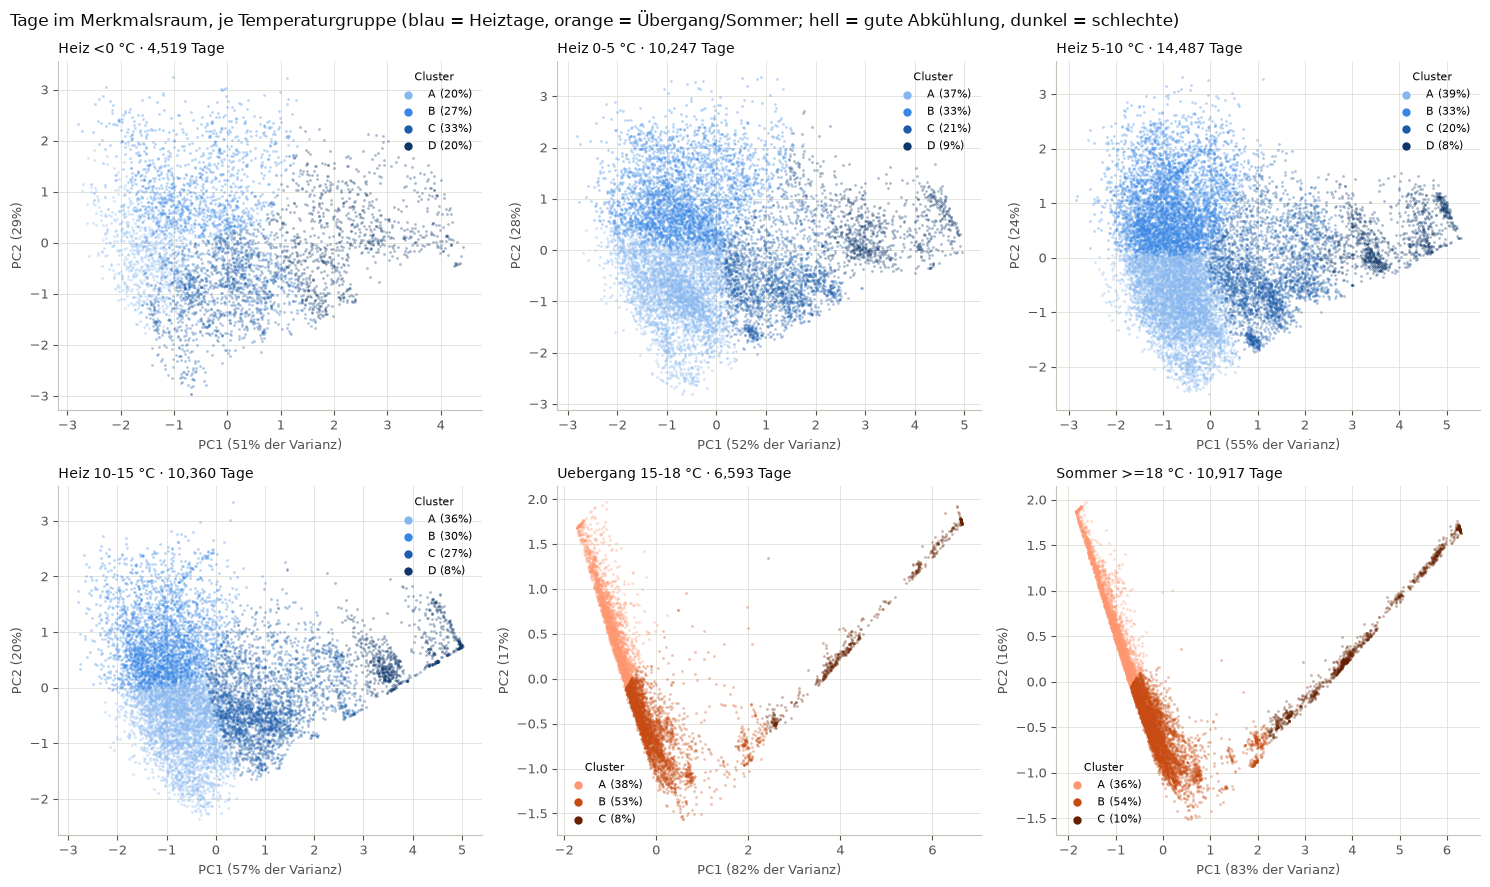

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (gruppe, e) in zip(axes.flat, ergebnisse.items()):
    pca = PCA(n_components=2, random_state=SEED).fit(e["Z"])
    P = pca.transform(e["Z"])
    farben = farben_fuer(gruppe, e["k"])
    for r in range(e["k"]):
        m = e["rang"] == r
        ax.scatter(P[m, 0], P[m, 1], s=4, alpha=0.35, color=farben[r], linewidths=0,
                   rasterized=True, label=f"{BUCHSTABEN[r]} ({m.mean():.0%})")
    ax.set_title(f"{gruppe} °C · {len(P):,} Tage", loc="left", fontsize=10, color=TINTE)
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} der Varianz)", fontsize=9, color=TINTE_LEISE)
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})", fontsize=9, color=TINTE_LEISE)
    legende = ax.legend(title="Cluster", fontsize=8, title_fontsize=8, markerscale=3, frameon=False)
    for h in legende.legend_handles:
        h.set_alpha(1)
    stil(ax)
for ax in list(axes.flat)[len(ergebnisse):]:
    ax.axis("off")
fig.suptitle("Tage im Merkmalsraum, je Temperaturgruppe (blau = Heiztage, orange = Übergang/Sommer; hell = gute Abkühlung, dunkel = schlechte)",
             x=0.01, ha="left", color=TINTE)
fig.tight_layout()
plt.show()

- Jeder Punkt ist ein Tag einer HAST. Die Achsen haben keine Einheit.
- Klar getrennte Wolken heißen echte Tagestypen. Eine durchgehende Wolke, die nur zerschnitten wird, heißt Kontinuum.

In [11]:
ladungen = []
for gruppe, e in ergebnisse.items():
    pca = PCA(n_components=2, random_state=SEED).fit(e["Z"])
    for i, achse in enumerate(["PC1", "PC2"]):
        ladungen.append({"gruppe": gruppe, "achse": achse,
                         "Anteil Varianz %": round(100 * pca.explained_variance_ratio_[i]),
                         **dict(zip(MERKMALE_JE_GRUPPE[gruppe], pca.components_[i].round(2)))})
display(pd.DataFrame(ladungen).set_index(["gruppe", "achse"]))

Anteil Varianz %  kwh_pro_m3  volumen_m3_pro_kw  \
gruppe          achse                                                    
Heiz <0         PC1                  51       -0.56               0.62   
                PC2                  29       -0.43               0.20   
Heiz 0-5        PC1                  52       -0.56               0.61   
                PC2                  28       -0.42               0.22   
Heiz 5-10       PC1                  55       -0.54               0.59   
                PC2                  24       -0.43               0.21   
Heiz 10-15      PC1                  57       -0.52               0.55   
                PC2                  20       -0.43               0.31   
Uebergang 15-18 PC1                  82       -0.50               0.62   
                PC2                  17        0.86               0.32   
Sommer >=18     PC1                  83       -0.51               0.61   
                PC2                  16        0.86               0.32   

                       spreizung_p90_p10_k  fluss_cv  nachtfluss_lh_pro_kw  
gruppe          achse                                                       
Heiz <0         PC1                  -0.22     -0.50                   NaN  
                PC2                   0.80      0.37                   NaN  
Heiz 0-5        PC1                  -0.24     -0.51                   NaN  
                PC2                   0.82      0.33                   NaN  
Heiz 5-10       PC1                  -0.31     -0.52                   NaN  
                PC2                   0.86      0.19                   NaN  
Heiz 10-15      PC1                  -0.40     -0.51                   NaN  
                PC2                   0.84      0.10                   NaN  
Uebergang 15-18 PC1                    NaN       NaN                  0.61  
                PC2                    NaN       NaN                  0.39  
Sommer >=18     PC1                    NaN       NaN                  0.60  
                PC2                    NaN       NaN                  0.40

Was steckt in PC1 und PC2?
- Jede Achse mischt alle Merkmale der Gruppe. Die Ladungen (Werte zwischen −1 und 1) sagen, wie stark. Ladung² = Anteil des Merkmals an der Achse (z. B. 0,59² ≈ 35 %).
- Gleiches Vorzeichen heißt: Die Merkmale wirken in dieselbe Richtung. Das Vorzeichen einer ganzen Achse ist beliebig. Leere Felder: Merkmal kommt in der Gruppe nicht vor.

**Heiztage**
- PC1 ist die Dauerdurchfluss-Achse (51–57 % der Unterschiede): Volumen je kW (rund 35 %), Abkühlung (rund 29 %, umgekehrt) und Durchfluss-Schwankung (rund 27 %, umgekehrt). Viel Wasser, gleichmäßiger Fluss, schlechte Abkühlung: Typ D liegt rechts.
- PC2 ist die Schwankungs-Achse (20–29 %): fast nur Streuung der Spreizung (rund 70 %). Typ B liegt oben. Die Streuung ist eine eigene Dimension, deshalb entsteht B als eigener Typ.
- PC1 und PC2 zeigen zusammen 77–80 % der Unterschiede.

**Übergang und Sommer**
- PC1 (82–83 %): Volumen je kW (rund 38 %) und Nachtfluss (rund 37 %). Trennt Dauerdurchfluss vom Rest.
- PC2 (16–17 %): vor allem Abkühlung (rund 74 %). Trennt gut (A) von mäßig (B).

**Grenze**
- Die PCA zeigt die Hauptunterschiede der Daten, nicht, wie stark ein Merkmal über die Cluster entscheidet. Das zeigt die Wichtigkeitstabelle in Abschnitt 9.

## 11 Liegen die Tage einer HAST zusammen?

- Konzentration einer HAST = Anteil ihrer Tage im häufigsten Cluster. 100 % heißt: alle Tage im selben Cluster.
- Vergleich mit Zufall: Die Clusterzuordnung wird innerhalb der Gruppe 200-mal gemischt (gleiche Clustergrößen). Liegt die echte Konzentration deutlich darüber, prägt die Station ihre Tage.
- Berücksichtigt werden HAST mit mindestens 10 geclusterten Tagen in der Gruppe.

,HAST,Median tatsaechlich,Median Zufall,Anteil HAST >= 80 % in einem Cluster,bei Zufall
gruppe,,,,,
Heiz <0,88,0.77,0.35,0.45,0.0
Heiz 0-5,88,0.80,0.39,0.50,0.0
Heiz 5-10,88,0.74,0.40,0.43,0.0
Heiz 10-15,86,0.68,0.37,0.30,0.0
Uebergang 15-18,86,0.86,0.54,0.57,0.0
Sommer >=18,81,0.88,0.54,0.60,0.0


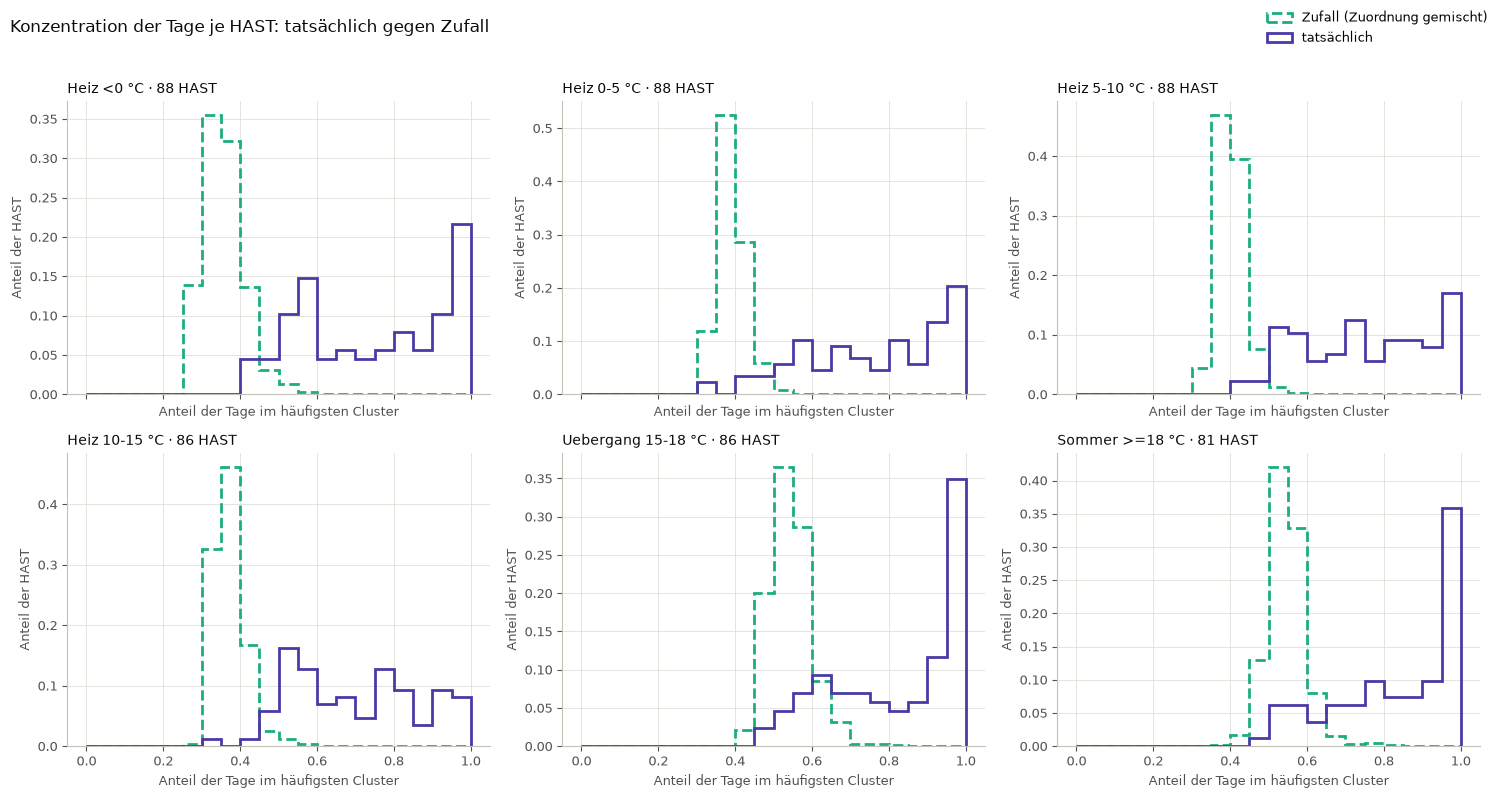

In [12]:
def konzentration(codes, rang, k):
    zaehl = np.bincount(codes * k + rang, minlength=(codes.max() + 1) * k).reshape(-1, k)
    return zaehl.max(axis=1) / zaehl.sum(axis=1)


rng = np.random.default_rng(SEED)
zeilen, verteilung = [], {}
for gruppe, e in ergebnisse.items():
    teil = e["teil"]
    genug = (teil["zaehler"].map(teil["zaehler"].value_counts()) >= MIN_TAGE_JE_HAST).to_numpy()
    if genug.sum() == 0:
        continue
    codes = pd.factorize(teil["zaehler"].to_numpy()[genug])[0]
    rang = e["rang"][genug].astype(int)
    echt = konzentration(codes, rang, e["k"])
    zufall = np.array([konzentration(codes, rng.permutation(rang), e["k"]) for _ in range(200)])
    verteilung[gruppe] = (echt, zufall.ravel())
    zeilen.append({"gruppe": gruppe, "HAST": len(echt),
                   "Median tatsaechlich": np.median(echt), "Median Zufall": np.median(zufall),
                   "Anteil HAST >= 80 % in einem Cluster": (echt >= 0.8).mean(),
                   "bei Zufall": (zufall >= 0.8).mean()})
display(pd.DataFrame(zeilen).set_index("gruppe").round(2))

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
kanten = np.linspace(0, 1, 21)
for ax, (gruppe, (echt, zufall)) in zip(axes.flat, verteilung.items()):
    ax.hist(zufall, bins=kanten, weights=np.full(len(zufall), 1 / len(zufall)), histtype="step",
            linewidth=2, linestyle="--", color=FARBE_ZUFALL, label="Zufall (Zuordnung gemischt)")
    ax.hist(echt, bins=kanten, weights=np.full(len(echt), 1 / len(echt)), histtype="step",
            linewidth=2, color=FARBE_TATSAECHLICH, label="tatsächlich")
    ax.set_title(f"{gruppe} °C · {len(echt)} HAST", loc="left", fontsize=10, color=TINTE)
    ax.set_xlabel("Anteil der Tage im häufigsten Cluster", fontsize=9, color=TINTE_LEISE)
    ax.set_ylabel("Anteil der HAST", fontsize=9, color=TINTE_LEISE)
    stil(ax)
for ax in list(axes.flat)[len(verteilung):]:
    ax.axis("off")
griffe, namen = axes.flat[0].get_legend_handles_labels()
fig.legend(griffe, namen, loc="upper right", frameon=False, fontsize=9)
fig.suptitle("Konzentration der Tage je HAST: tatsächlich gegen Zufall", x=0.01, ha="left", color=TINTE)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

- Lesehilfe: Liegt die violette Kurve (tatsächlich) deutlich rechts von der türkisen (Zufall, gestrichelt), landen die Tage einer HAST überwiegend im selben Cluster. Sind beide ähnlich, beschreiben die Cluster Zustände, die bei vielen HAST vorkommen.
- Ergebnis: Median der Konzentration 0,68–0,88, bei Zufall 0,35–0,54. 30–60 % der HAST haben mindestens 80 % ihrer Tage in einem Cluster, bei Zufall 0,0.
- Die Cluster beschreiben damit eher Stationen als Tageszustände.
- Interessant für später sind HAST, die zwischen Clustern wechseln. Laut Folie 5 deutet Wechseln auf ein Regelproblem hin, gleichbleibend schlechte Tage eher auf einen Defekt.

## 12 Cluster je HAST im Zeitverlauf

- Ein Bild für alle HAST: eine Zeile je HAST, eine Farbe je Tag nach Cluster.
- Sortiert von überwiegend guten zu überwiegend schlechten Typen.

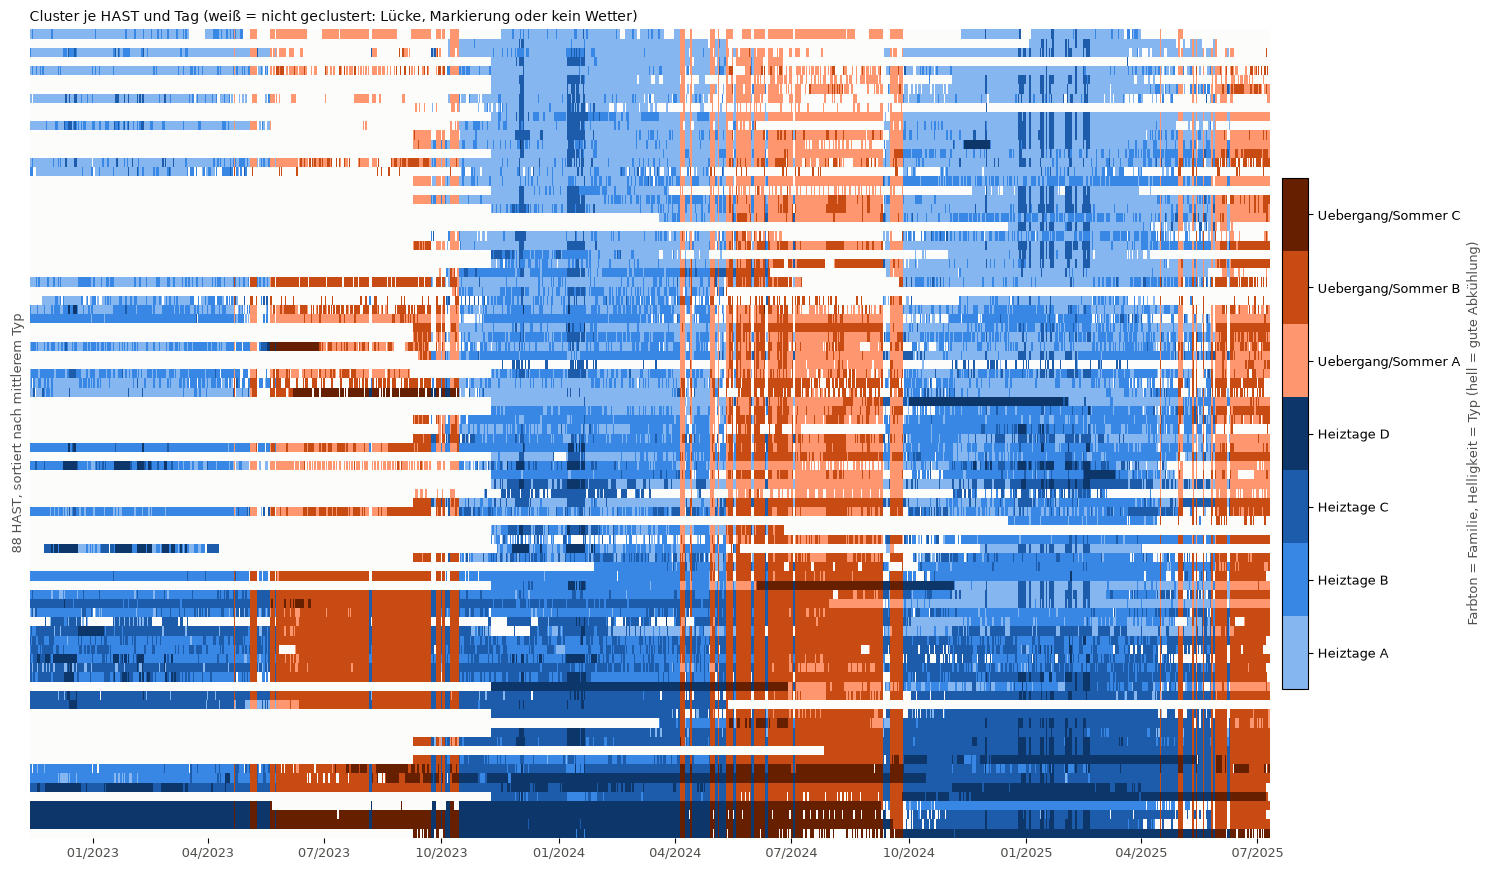

In [13]:
familie_von = {g: ("Uebergang/Sommer" if ist_sommerfamilie(g) else "Heiztage", e["k"])
               for g, e in ergebnisse.items()}
farben, namen, versatz = [], [], {}
for gruppe, (familie, k) in familie_von.items():
    if (familie, k) not in versatz:
        versatz[(familie, k)] = len(farben)
        farben += farben_fuer(gruppe, k)
        namen += [f"{familie} {BUCHSTABEN[r]}" for r in range(k)]

g = geclustert["gruppe"].astype(str)
farbindex = geclustert["cluster_rang"] + g.map(lambda x: versatz[familie_von[x]])
relativ = geclustert["cluster_rang"] / (g.map(lambda x: familie_von[x][1]) - 1)  #0 = A ... 1 = schlechtester Typ
zeit = (geclustert.assign(farbindex=farbindex)
        .pivot_table(index="zaehler", columns="datum", values="farbindex", aggfunc="first"))
zeit = zeit.reindex(columns=pd.date_range(zeit.columns.min(), zeit.columns.max(), freq="D"))
zeit = zeit.loc[relativ.groupby(geclustert["zaehler"]).mean().sort_values().index]

farbskala = ListedColormap(farben)
farbskala.set_bad(FLAECHE)
fig, ax = plt.subplots(figsize=(15, max(4, 0.1 * len(zeit))))
bild = ax.imshow(np.ma.masked_invalid(zeit.to_numpy(dtype=float)), aspect="auto", interpolation="none",
                 cmap=farbskala, vmin=-0.5, vmax=len(farben) - 0.5)
quartale = list(pd.date_range(zeit.columns.min(), zeit.columns.max(), freq="QS"))
ax.set_xticks([zeit.columns.get_loc(d) for d in quartale])
ax.set_xticklabels([d.strftime("%m/%Y") for d in quartale], fontsize=9, color=TINTE_LEISE)
ax.set_yticks([])
ax.set_ylabel(f"{len(zeit)} HAST, sortiert nach mittlerem Typ", fontsize=9, color=TINTE_LEISE)
for seite in ax.spines.values():
    seite.set_visible(False)
leiste = fig.colorbar(bild, ax=ax, ticks=range(len(farben)), fraction=0.02, pad=0.01)
leiste.ax.set_yticklabels(namen, fontsize=9)
leiste.set_label("Farbton = Familie, Helligkeit = Typ (hell = gute Abkühlung)", fontsize=9, color=TINTE_LEISE)
ax.set_title("Cluster je HAST und Tag (weiß = nicht geclustert: Lücke, Markierung oder kein Wetter)",
             loc="left", fontsize=10, color=TINTE)
fig.tight_layout()
plt.show()

- Jede Spalte ist ein Tag. Zählernummern sind bewusst nicht beschriftet.
- Farbton = Familie: Blau für Heiztage (A–D), Orange für Übergang und Sommer (A–C). Helligkeit = Typ: hell = gute Abkühlung, dunkel = schlechte.
- Durchgehend gleiche Farbe: Die HAST bleibt in ihrem Cluster. Farbwechsel ab einem Datum: Der Zustand ändert sich, etwa nach einer Reparatur.
- Solche Wechsel sind die Brücke zum Abgleich mit den Begehungen.

## 13 Ergebnis speichern

- Speichert Tageszeilen, Clusteranteile je HAST und den Lauf-Kontext unter `data/processed/`.

In [14]:
AUSGABE.parent.mkdir(parents=True, exist_ok=True)
SPALTEN_AUS = ["zaehler", "datum", "gruppe", "t_mittel_c", "nutzbar", "grund", "cluster",
               "kwh_pro_m3", "spreizung_k", "energie_kwh", "volumen_m3", "anschlusswert_kw",
               "volumen_m3_pro_kw", "spreizung_p90_p10_k", "fluss_cv", "nachtfluss_lh",
               "nachtfluss_lh_pro_kw", "n_stunden", "n_aktiv", "zaehler_spanne_h",
               "fluss_mittel_lh", "leistung_mittel_kw", "vorlauf_c", "ruecklauf_c"]
tage[SPALTEN_AUS].to_csv(AUSGABE, index=False)

anteile = (geclustert.groupby(["zaehler", "gruppe", "cluster"], observed=True).size()
           .groupby(level=[0, 1], observed=True).transform(lambda s: s / s.sum())
           .rename("anteil").reset_index())
anteile.to_csv(AUSGABE.with_name("hast_tage_clusteranteile.csv"), index=False)

meta = {
    "erzeugt": pd.Timestamp.now().isoformat(timespec="seconds"),
    "wetterstation": "DWD 2600 Kitzingen",
    "gruppen": GRUPPEN,
    "merkmale_je_gruppe": MERKMALE_JE_GRUPPE,
    "k_je_gruppe": {g: e["k"] for g, e in ergebnisse.items()},
    "referenz_je_gruppe": {g: e["referenz"] for g, e in ergebnisse.items()},
    "silhouette": json.loads(silhouette.round(3).to_json(orient="index")),
    "schwellen": {"max_abstand_h": MAX_ABSTAND_H, "aktiv_fluss_lh": AKTIV_FLUSS_LH,
                  "min_aktiv_stunden": MIN_AKTIV_STUNDEN, "min_stunden": MIN_STUNDEN,
                  "min_energie_kwh": MIN_ENERGIE_KWH, "max_kwh_pro_m3": MAX_KWH_PRO_M3,
                  "steht_leistung_kw": STEHT_LEISTUNG_KW, "min_tage_je_hast": MIN_TAGE_JE_HAST},
    "tageszeilen": int(len(tage)),
    "nutzbar": int(tage["nutzbar"].sum()),
    "geclustert": int(len(geclustert)),
}
AUSGABE.with_suffix(".json").write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Tageszeilen   -> {AUSGABE.name}  ({len(tage):,} Zeilen)")
print(f"Clusteranteile -> hast_tage_clusteranteile.csv  ({len(anteile):,} Zeilen)")
print(f"Lauf-Kontext  -> {AUSGABE.with_suffix('.json').name}")

Tageszeilen   -> hast_tage.csv  (85,983 Zeilen)
Clusteranteile -> hast_tage_clusteranteile.csv  (1,248 Zeilen)
Lauf-Kontext  -> hast_tage.json


- `hast_tage.csv`: alle 85.983 Tageszeilen mit Merkmalen, Markierungen und Cluster.
- `hast_tage_clusteranteile.csv` (1.248 Zeilen): je HAST und Gruppe der Anteil ihrer Tage pro Cluster. Grundlage für Stationsprofile nach Folie 5.
- `hast_tage.json`: Parameter, K, Silhouette und Zeilenzahlen dieses Laufs.
- Datenschutz: Die CSVs enthalten Zählernummern. `data/processed/` ist gitignored und bleibt es.

## Zusammenfassung & Bewertung

**Ergebnis**
- 85.983 Tageszeilen von 93 Zählern, davon 62.734 nutzbar (73 %). Am meisten kostet die Markierung „unter 12 Messstunden“ (16.045 Tage).
- An Heiztagen entstehen in allen Temperaturbändern dieselben vier Typen: gute Abkühlung (A), stark schwankend (B), gleichmäßig schwach (C), Dauerdurchfluss (D). In Übergang und Sommer drei Typen: gut, mäßig, Dauerdurchfluss.
- Die Tage einer HAST liegen deutlich häufiger im selben Cluster als bei Zufall (Median 0,68–0,88 gegen 0,35–0,54). Die Cluster beschreiben eher Stationen als Tage.

**Belastbar**
- Dauerdurchfluss (D an Heiztagen mit 16 HAST, C im Sommer mit 14 HAST) grenzt sich klar ab.
- Übergang und Sommer sind klar getrennt (Silhouette 0,739 und 0,743 bei K = 2, 0,494 und 0,503 bei K = 3).
- Die Cluster unterscheiden sich in mehreren Merkmalen, nicht nur in einem: Jedes Merkmal erklärt mindestens 40 % seiner Unterschiede.
- Tagesenergie und Tagesvolumen kommen aus Zählerständen und sind nicht durch Momentaufnahmen verzerrt.

**Schwach**
- An Heiztagen ist die Struktur schwach (Silhouette 0,27–0,30 bei K = 4). A, B und C gehen fließend ineinander über.
- Bei Frost passen die Typen schlechter zur Referenz (Abstand 1,12).
- Im Sommer sind nur 60 % der Tage nutzbar. Es bleiben eher größere, verbrauchsstarke Stationen übrig.
- Die Streuung stammt aus Momentaufnahmen und enthält auch zufällige Warmwasserzapfungen.

**Offen**
- Warum so viele Tage weniger als 12 Messstunden haben.
- Zählertausch ist nicht zusammengeführt: Eine HAST mit Tausch erscheint als zwei Zähler.
- K (4 an Heiztagen, 3 in Übergang und Sommer) und alle Schwellen sind Startwerte. Wetterdaten nur bis 31.12.2025.
- Ob Farbwechsel im Zeitverlauf zu bekannten Ereignissen passen, etwa dem Ventilfall im September 2024, ist noch nicht geprüft. Das ist der Einstieg in den Abgleich mit den Begehungen.
- Kostet die Energieschwelle im Sommer zu viele Tage, wären Wochenwerte statt Tageswerte eine Option.